In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load the cleaned tickets
file_path = "ADEI_Cleaning_Results.xlsx"
df = pd.read_excel(file_path, sheet_name="Cleaned_Tickets")


In [3]:
# Prepare labels and timestamps
df["status"] = df["status"].astype("string").str.strip().str.title()
df["channel"] = df["channel"].astype("string").str.strip()
df["category"] = df["category"].astype("string").str.strip()

df["opened_at"] = pd.to_datetime(df["opened_at"], errors="coerce")
df["resolved_at"] = pd.to_datetime(df["resolved_at"], errors="coerce")

In [4]:
# Calculate resolution time in hours
df["resolution_hours"] = (
    df["resolved_at"] - df["opened_at"]
).dt.total_seconds() / 3600

In [5]:
# Valid resolution times: resolved status, both dates present, no negative duration
valid_resolution = (
    df["status"].eq("Resolved")
    & df["resolution_hours"].notna()
    & df["resolution_hours"].ge(0)
)

resolved_df = df.loc[valid_resolution].copy()

In [6]:
# ----------------------------------------------------------
# 1. Ticket status and resolution
# ----------------------------------------------------------
status_summary = (
    df["status"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .reset_index(name="ticket_count")
)

status_summary["percent_of_tickets"] = (
    status_summary["ticket_count"] / len(df) * 100
)

print("Ticket status summary")
display(status_summary.round(1))

print("Total tickets:", len(df))
print("Resolved tickets:", int(df["status"].eq("Resolved").sum()))
print(
    "Open or pending tickets:",
    int(df["status"].isin(["Open", "Pending"]).sum())
)

Ticket status summary


,status,ticket_count,percent_of_tickets
0,Resolved,96,69.1
1,Pending,22,15.8
2,Open,19,13.7
3,Closed,1,0.7
4,Escalated,1,0.7


Total tickets: 139
Resolved tickets: 96
Open or pending tickets: 41


In [7]:
# ----------------------------------------------------------
# 2–3. Communication channel performance
# ----------------------------------------------------------
channel_summary = (
    df.groupby("channel", dropna=False)
    .size()
    .rename("ticket_volume")
    .to_frame()
    .join(
        resolved_df.groupby("channel", dropna=False)["resolution_hours"]
        .agg(
            valid_resolution_sample="count",
            median_resolution_hours="median"
        )
    )
    .reset_index()
    .sort_values("ticket_volume", ascending=False)
)

print("Channel performance")
display(channel_summary.round(2))

Channel performance


,channel,ticket_volume,valid_resolution_sample,median_resolution_hours
3,Web,51,34,4.58
0,Email,47,34,5.55
4,WhatsApp,39,24,4.73
1,SMS,1,1,55.08
2,Unknown,1,1,8.60


In [8]:
# ----------------------------------------------------------
# 4. Most common customer issues
# ----------------------------------------------------------
category_volume = (
    df["category"]
    .value_counts(dropna=False)
    .rename_axis("category")
    .reset_index(name="ticket_count")
)

category_volume["percent_of_tickets"] = (
    category_volume["ticket_count"] / len(df) * 100
)

print("Ticket volume by category")
display(category_volume.round(1))

Ticket volume by category


,category,ticket_count,percent_of_tickets
0,Access,36,25.9
1,Technical,36,25.9
2,Billing,34,24.5
3,General,31,22.3
4,Other,1,0.7
5,Unknown,1,0.7


In [9]:
# ----------------------------------------------------------
# 5. Resolution performance by category
# ----------------------------------------------------------
category_resolution = (
    resolved_df.groupby("category", dropna=False)["resolution_hours"]
    .agg(
        valid_resolution_sample="count",
        median_resolution_hours="median"
    )
    .reset_index()
    .sort_values("median_resolution_hours", ascending=False)
)

print("Category resolution performance")
display(category_resolution.round(2))

Category resolution performance


,category,valid_resolution_sample,median_resolution_hours
4,Unknown,1,10.78
2,General,20,9.10
3,Technical,25,7.82
1,Billing,25,4.20
0,Access,23,2.37


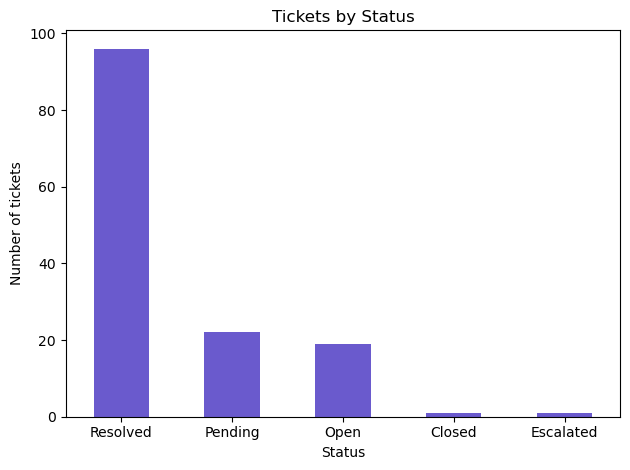

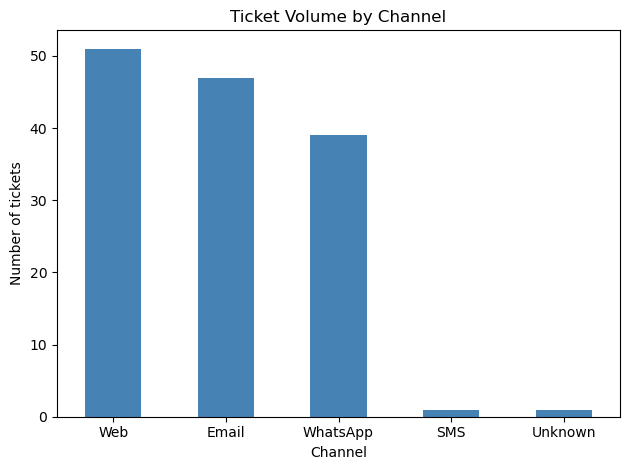

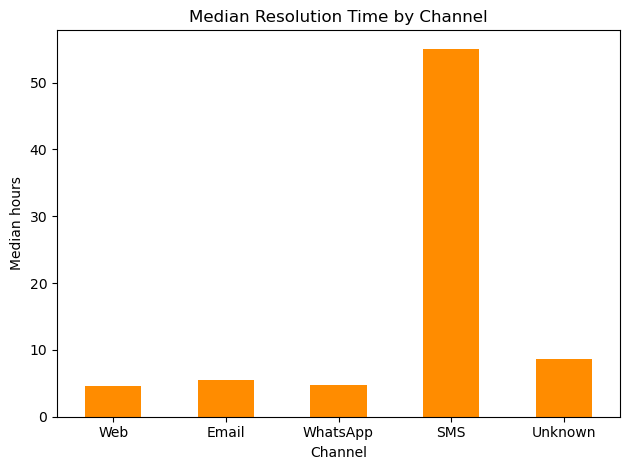

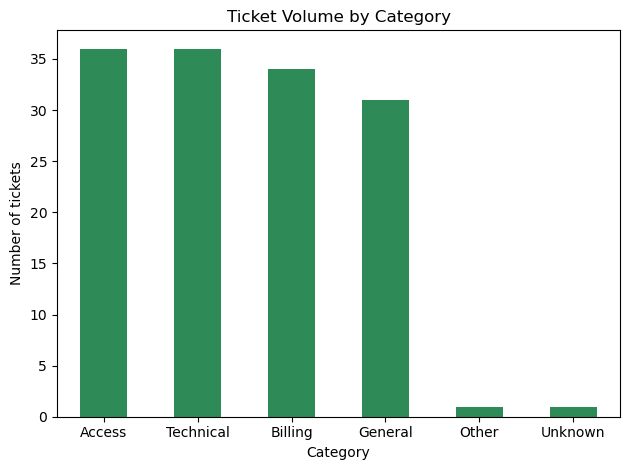

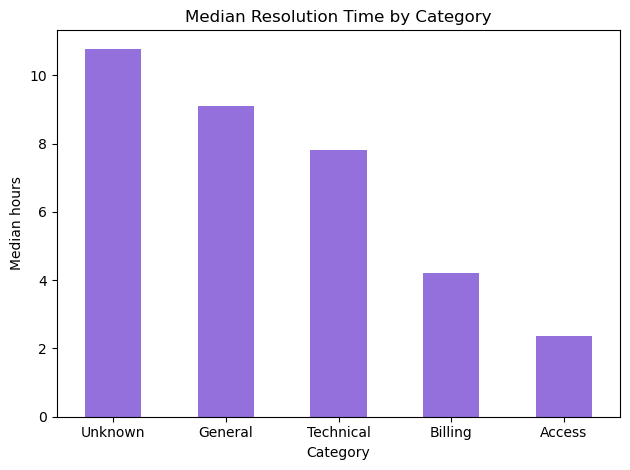

In [10]:
# ----------------------------------------------------------
# Charts
# ----------------------------------------------------------

# Ticket counts by status
status_summary.plot(
    x="status",
    y="ticket_count",
    kind="bar",
    legend=False,
    title="Tickets by Status",
    xlabel="Status",
    ylabel="Number of tickets",
    color="slateblue"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Ticket volume by channel
channel_summary.plot(
    x="channel",
    y="ticket_volume",
    kind="bar",
    legend=False,
    title="Ticket Volume by Channel",
    xlabel="Channel",
    ylabel="Number of tickets",
    color="steelblue"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Median resolution time by channel
channel_summary.dropna(subset=["median_resolution_hours"]).plot(
    x="channel",
    y="median_resolution_hours",
    kind="bar",
    legend=False,
    title="Median Resolution Time by Channel",
    xlabel="Channel",
    ylabel="Median hours",
    color="darkorange"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Ticket volume by category
category_volume.plot(
    x="category",
    y="ticket_count",
    kind="bar",
    legend=False,
    title="Ticket Volume by Category",
    xlabel="Category",
    ylabel="Number of tickets",
    color="seagreen"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Median resolution time by category
category_resolution.plot(
    x="category",
    y="median_resolution_hours",
    kind="bar",
    legend=False,
    title="Median Resolution Time by Category",
    xlabel="Category",
    ylabel="Median hours",
    color="mediumpurple"
)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Finding 1 
Channel performance: Web had the highest ticket volume, with 51 tickets. Its median resolution time was 4.58 hours across 34 valid resolutions. Email had 47 tickets and a 5.55-hour median (34 valid resolutions); WhatsApp had 39 tickets and a 4.73-hour median (24 valid resolutions). The single SMS ticket took 55.08 hours and breached the SLA, but a sample of one is too small to judge SMS performance generally.

Finding 2 
Weekly trend: Ticket volume was steady at 34–35 tickets per week. The week starting 26 October had the highest median resolution time, 7.10 hours (25 valid resolutions), and the only breach: 1 of 25 tickets (4%). Across all channels, 94 of 139 cleaned tickets had valid resolution times.

Recommended action: Review the delayed SMS ticket and the breach in the week starting 26 October to understand what caused the delays. Keep monitoring before making broader channel changes.

Limitation: Resolution measures exclude unresolved tickets and records with missing or invalid timestamps. That means the medians and breach rates describe only tickets with usable resolution data. The SMS result is especially uncertain because it is based on one ticket.